# Repérer dès l'inscription les étudiants à risque de faibles résultats

## Contexte et besoin métier
En Colombie, les étudiants en ingénierie passent en fin de cursus un examen
national, le Saber Pro. Une université souhaite identifier, dès l'inscription,
les étudiants risquant d'obtenir un score faible, afin de leur proposer un
accompagnement ciblé.

**Objectif :** prédire si un étudiant obtiendra un score global Saber Pro faible,
à partir de ses résultats au lycée (Saber 11) et de son profil.

**Source :** Delahoz-Dominguez E., Zuluaga R., Fontalvo-Herrera T. (2020),
*Dataset of academic performance evolution for engineering students*
(https://data.mendeley.com/datasets/83tcx8psxv/1).

# Partie 1
## Étape 1 : Importation des données

In [1383]:
# Manipulation des données et visualisation
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [1384]:
# Affichage de toutes les colonnes et style homogène des graphiques
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [ ]:
# Chargement du dataset : une ligne correspond à un étudiant
df = pd.read_excel("dataset/data_academic_performance.xlsx")
print("Dimensions du dataset :", df.shape)


### Description des variables
| Famille | Colonnes | Contenu |
|---|---|---|
| Identifiants | `COD_S11`, `Cod_SPro` | Codes de l'étudiant aux deux examens |
| Profil familial | `GENDER`, `EDU_FATHER`, `EDU_MOTHER`, `OCC_FATHER`, `OCC_MOTHER`, `PEOPLE_HOUSE`, `JOB` | Genre, études et profession des parents, taille du foyer, emploi de l'étudiant |
| Niveau socio-économique | `STRATUM`, `SISBEN`, `REVENUE`, `SEL`, `SEL_IHE` | Strate du logement (1 à 6), aides sociales, revenus du foyer, niveau socio-économique |
| Équipement du foyer | `INTERNET`, `TV`, `COMPUTER`, `WASHING_MCH`, `MIC_OVEN`, `CAR`, `DVD`, `FRESH`, `PHONE`, `MOBILE` | Yes / No |
| Lycée | `SCHOOL_NAME`, `SCHOOL_NAT`, `SCHOOL_TYPE` | Nom, public / privé, type de lycée |
| Scores Saber 11 (lycée, sur 100) | `MAT_S11`, `CR_S11`, `CC_S11`, `BIO_S11`, `ENG_S11` | Mathématiques, lecture critique, compétences citoyennes, biologie, anglais |
| Université | `UNIVERSITY`, `ACADEMIC_PROGRAM` | Établissement, spécialité d'ingénierie |
| Scores Saber Pro (fin de cursus) | `QR_PRO`, `CR_PRO`, `CC_PRO`, `ENG_PRO`, `WC_PRO`, `FEP_PRO`, `G_SC` | Six épreuves et le **score global**, à partir duquel est construite la cible |
| Classements | `PERCENTILE`, `2ND_DECILE`, `QUARTILE` | Position de l'étudiant, calculée à partir de `G_SC` |

## Étape 2 : Exploration des données

In [ ]:
# Dimensions du dataset : (nombre de lignes, nombre de colonnes)
df.shape

(12411, 45)

In [ ]:
# Aperçu des premières lignes
df.head()

,COD_S11,GENDER,EDU_FATHER,EDU_MOTHER,OCC_FATHER,OCC_MOTHER,STRATUM,SISBEN,PEOPLE_HOUSE,Unnamed: 9,INTERNET,TV,COMPUTER,WASHING_MCH,MIC_OVEN,CAR,DVD,FRESH,PHONE,MOBILE,REVENUE,JOB,SCHOOL_NAME,SCHOOL_NAT,SCHOOL_TYPE,MAT_S11,CR_S11,CC_S11,BIO_S11,ENG_S11,Cod_SPro,UNIVERSITY,ACADEMIC_PROGRAM,QR_PRO,CR_PRO,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
0,SB11201210000129,F,Incomplete Professional Education,Complete technique or technology,Technical or professional level employee,Home,Stratum 4,It is not classified by the SISBEN,Three,NaN,Yes,Yes,Yes,Yes,No,No,Yes,Yes,Yes,Yes,Between 1 and less than 2 LMMW,No,COL NUEVO CAMBRIDGE,PRIVATE,ACADEMIC,71,81,61,86,82,EK201830142293,UNIVERSIDAD DE SANTANDER - UDES-BUCARAMANGA,INDUSTRIAL ENGINEERING,71,93,71,93,79,181,180,91,5,4,2,2
1,SB11201210000137,F,Complete Secundary,Complete professional education,Entrepreneur,Independent professional,Stratum 5,It is not classified by the SISBEN,Three,NaN,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,10 or more LMMW,No,COL LA QUINTA DEL PUENTE,PRIVATE,ACADEMIC,83,75,66,100,88,EK201830002633,UNIVERSIDAD DE LOS ANDES-BOGOTÁ D.C.,INDUSTRIAL ENGINEERING,97,38,86,98,78,201,182,92,5,4,4,4
2,SB11201210005154,M,Not sure,Not sure,Independent,Home,Stratum 2,Level 2,Five,NaN,No,No,Yes,Yes,No,No,Yes,Yes,Yes,No,Between 1 and less than 2 LMMW,"Yes, 20 hours or more per week",CENT EDUC PAULO FREIRE ...,PRIVATE,ACADEMIC,52,49,38,46,42,EK201830196510,UNIVERSIDAD NACIONAL ABIERTA Y A DISTANCIA UNA...,ELECTRONIC ENGINEERING,17,1,18,43,22,113,113,7,1,1,1,1
3,SB11201210007504,F,Not sure,Not sure,Other occupation,Independent,Stratum 2,It is not classified by the SISBEN,Three,NaN,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Between 2 and less than 3 LMMW,No,LICEO ANDINO,PRIVATE,ACADEMIC,56,55,51,64,73,EK201830031665,UNIVERSIDAD CATOLICA DE PEREIRA-PEREIRA,INDUSTRIAL ENGINEERING,65,35,76,80,48,137,157,67,4,3,2,2
4,SB11201210007548,M,Complete professional education,Complete professional education,Executive,Home,Stratum 4,It is not classified by the SISBEN,One,NaN,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Between 7 and less than 10 LMMW,No,LIC TALLER SAN MIGUEL,PRIVATE,ACADEMIC,80,65,76,85,92,EK201830130461,UNIVERSIDAD INDUSTRIAL DE SANTANDER-BUCARAMANGA,INDUSTRIAL ENGINEERING,94,94,98,100,71,189,198,98,5,4,4,2


In [ ]:
# Type de chaque colonne et nombre de valeurs renseignées
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12411 entries, 0 to 12410
Data columns (total 45 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   COD_S11           12411 non-null  str    
 1   GENDER            12411 non-null  str    
 2   EDU_FATHER        12411 non-null  object 
 3   EDU_MOTHER        12411 non-null  object 
 4   OCC_FATHER        12411 non-null  object 
 5   OCC_MOTHER        12411 non-null  object 
 6   STRATUM           12411 non-null  object 
 7   SISBEN            12411 non-null  object 
 8   PEOPLE_HOUSE      12411 non-null  object 
 9   Unnamed: 9        0 non-null      float64
 10  INTERNET          12411 non-null  str    
 11  TV                12411 non-null  str    
 12  COMPUTER          12411 non-null  str    
 13  WASHING_MCH       12411 non-null  str    
 14  MIC_OVEN          12411 non-null  str    
 15  CAR               12411 non-null  str    
 16  DVD               12411 non-null  str    
 17  FRES

In [ ]:
# Répartition des colonnes par type
print("Nombre de colonnes par type :")
print(df.dtypes.value_counts())

Nombre de colonnes par type :
str        18
int64      17
object      9
float64     1
Name: count, dtype: int64


In [ ]:
# Modalités des colonnes texte (hors identifiants et noms d'établissements)
colonnes_texte = ["GENDER", "EDU_FATHER", "EDU_MOTHER", "OCC_FATHER", "OCC_MOTHER",
                  "STRATUM", "SISBEN", "PEOPLE_HOUSE", "REVENUE", "JOB",
                  "SCHOOL_NAT", "SCHOOL_TYPE"]

for col in colonnes_texte:
    print(f"{col} : {df[col].unique()}\n")

GENDER : <StringArray>
['F', 'M']
Length: 2, dtype: str

EDU_FATHER : ['Incomplete Professional Education' 'Complete Secundary' 'Not sure'
 'Complete professional education' 'Incomplete Secundary'
 'Incomplete technical or technological'
 'Complete technique or technology' 'Incomplete primary '
 'Complete primary ' 'Postgraduate education' 0 'Ninguno']

EDU_MOTHER : ['Complete technique or technology' 'Complete professional education'
 'Not sure' 'Complete Secundary' 'Incomplete technical or technological'
 'Incomplete primary ' 'Incomplete Secundary'
 'Incomplete Professional Education' 'Postgraduate education'
 'Complete primary ' 0 'Ninguno']

OCC_FATHER : ['Technical or professional level employee' 'Entrepreneur ' 'Independent'
 'Other occupation' 'Executive' 'Small entrepreneur '
 'Independent professional' 'Operator' 0 'Retired'
 'Auxiliary or Administrative' 'Home']

OCC_MOTHER : ['Home' 'Independent professional' 'Independent' 'Executive' 'Operator'
 'Entrepreneur ' 'Small entr

In [ ]:
# Répartition des colonnes par type
print("Nombre de colonnes par type :")
print(df.dtypes.value_counts())

Nombre de colonnes par type :
str        18
int64      17
object      9
float64     1
Name: count, dtype: int64


### Observations

**Structure :** 12 411 étudiants, 45 colonnes.
- 17 colonnes numériques int : scores, classements, niveaux socio-économiques.
- 28 colonnes de texte : profil, équipement, lycée, université.

**Anomalies détectées :**

| Anomalie | Colonnes concernées | Exemple | Traitement (étape 3) |
|---|---|---|---|
| Colonne vide | `Unnamed: 9` | Aucune valeur | Suppression |
| Valeurs manquantes codées par `0` | `EDU_FATHER`, `EDU_MOTHER`, `OCC_FATHER`, `OCC_MOTHER`, `STRATUM`, `SISBEN`, `PEOPLE_HOUSE`, `REVENUE`, `JOB` | `0` au milieu de modalités texte | Conversion en valeurs manquantes, puis imputation |
| Modalités en espagnol | `PEOPLE_HOUSE`, `EDU_FATHER`, `EDU_MOTHER`, `SISBEN` | `Nueve` (9), `Once` (11), `Ninguno` (aucun) | Traduction |
| Espaces en fin de valeur | `EDU_FATHER`, `EDU_MOTHER`, `OCC_FATHER`, `OCC_MOTHER` | `'Complete primary '`, `'Entrepreneur '` | Suppression des espaces |
| Réponses imprécises | `EDU_FATHER`, `EDU_MOTHER`, `SCHOOL_TYPE` | `Not sure`, `Not apply` | Conservées comme modalités à part |

**À noter :** pandas ne détecte pas les `0` comme valeurs manquantes
(`info()` indique toutes les colonnes complètes, sauf `Unnamed: 9`).
Ils sont repérables par le type `object` des 9 colonnes concernées,
qui mélangent texte et nombres, et par la commande `unique()`.

## Étape 3 : Data preprocessing
Les anomalies relevées à l'étape 2 sont traitées une à une, selon la même
démarche : constat, décision, vérification.

### 3.1 Colonnes inutiles et fuite de données
Nous supprimons :
- `Unnamed: 9`, entièrement vide ;
- `SCHOOL_NAME` et `UNIVERSITY`, qui comptent respectivement 3 735 et 134
  valeurs distinctes donc pas cohérent avec le decision tree
- les sous-scores Saber Pro (`QR_PRO`, `CR_PRO`, `CC_PRO`, `ENG_PRO`,
  `WC_PRO`, `FEP_PRO`) et les classements (`PERCENTILE`, `2ND_DECILE`,
  `QUARTILE`). Mesurés en fin de cursus ou calculés à partir du score
  global, ils sont inconnus au moment de l'inscription : les conserver
  créerait une **fuite de données** et augmenterait artificiellement le ROC

In [ ]:
# Colonnes vides, inexploitables ou indisponibles à l'inscription
colonnes_a_supprimer = ["Unnamed: 9", "SCHOOL_NAME", "UNIVERSITY",
                        "QR_PRO", "CR_PRO", "CC_PRO", "ENG_PRO", "WC_PRO", "FEP_PRO",
                        "PERCENTILE", "2ND_DECILE", "QUARTILE"]

df = df.drop(columns=colonnes_a_supprimer)
print("Dimensions après suppression des colonnes :", df.shape)

Dimensions après suppression des colonnes : (12411, 33)


In [ ]:
# Lignes strictement identiques, puis étudiants enregistrés plusieurs fois
print("Lignes identiques :", df.duplicated().sum())
# ATTENTION, 1 ID SABER PRO = 1 élève
print("Étudiants en double (même code Saber Pro) :", df.duplicated(subset="Cod_SPro").sum())

Lignes identiques : 0
Étudiants en double (même code Saber Pro) : 16


In [ ]:
# Affichage des étudiants en double, triés par code pour voir les paires côte à côte
doublons = df[df.duplicated(subset="Cod_SPro", keep=False)].sort_values("Cod_SPro")

print("Lignes concernées :", len(doublons))
doublons[["Cod_SPro", "COD_S11", "GENDER", "MAT_S11", "CR_S11", "ENG_S11", "G_SC"]].head(10)

Lignes concernées : 32


,Cod_SPro,COD_S11,GENDER,MAT_S11,CR_S11,ENG_S11,G_SC
6524,EK201830012603,SB11201320110284,M,70,58,72,168
2259,EK201830012603,SB11201220313289,M,69,54,75,168
8035,EK201830013197,SB11201320225581,F,50,46,58,118
604,EK201830013197,SB11201220043502,F,54,51,49,118
2023,EK201830017763,SB11201220288842,M,56,59,49,150
4289,EK201830017763,SB11201310002204,M,60,56,52,150
4648,EK201830022057,SB11201310072215,M,56,64,68,172
2659,EK201830022057,SB11201220340907,M,64,62,67,172
2463,EK201830030238,SB11201220326795,M,75,57,80,162
8250,EK201830030238,SB11201320242054,M,87,66,85,162


### 3.2 Doublons
Aucune ligne n'est strictement identique, mais **16 étudiants** apparaissent
deux fois sous le même code Saber Pro. Leurs deux lignes partagent le même
score global, mais diffèrent par le code et les scores Saber 11 : le code
lycée contenant l'année de l'examen (ex. `SB112012…`, `SB112013…`), ces
étudiants ont passé l'examen du lycée deux fois.

Nous conservons la **tentative la plus récente**, celle dont disposait
l'université au moment de l'inscription car représente l'état réel de l'élève avant études supérieures

In [ ]:
# Tri par code lycée (qui contient l'année), puis conservation de la tentative la plus récente
df = df.sort_values("COD_S11")
df = df.drop_duplicates(subset="Cod_SPro", keep="last")
df = df.drop(columns=["COD_S11", "Cod_SPro"])
print("Dimensions après suppression des doublons :", df.shape)

Dimensions après suppression des doublons : (12395, 31)


### 3.3 Valeurs manquantes

In [ ]:
# isnull() ne détecte aucune valeur manquante car for each column isnull() = 0 donc somme de isnull() = 0 également, on sait cependant qu'il y a des valeurs 0 suite à l'exploration
print("Valeurs manquantes détectées par isnull() :", df.isnull().sum().sum())

Valeurs manquantes détectées par isnull() : 0


In [ ]:
# Conversion des 0 en valeurs manquantes explicites (NaN)
colonnes_avec_zero = ["EDU_FATHER", "EDU_MOTHER", "OCC_FATHER", "OCC_MOTHER",
                      "STRATUM", "SISBEN", "PEOPLE_HOUSE", "REVENUE", "JOB"]

df[colonnes_avec_zero] = df[colonnes_avec_zero].replace(0, np.nan)

In [ ]:
# Nombre et part de valeurs manquantes, et modalité qui les remplacera (le mode)
manquants = df[colonnes_avec_zero].isnull().sum()
pourcentage = (manquants / len(df) * 100).round(1)
modes = [df[col].mode()[0] for col in colonnes_avec_zero]

print(pd.DataFrame({"Manquants": manquants, "%": pourcentage, "Remplacé par": modes},
                   index=colonnes_avec_zero))
print("\nÉtudiants avec au moins une valeur manquante :",
      df[colonnes_avec_zero].isnull().any(axis=1).sum())

              Manquants    %                        Remplacé par
EDU_FATHER          384  3.1     Complete professional education
EDU_MOTHER          380  3.1                  Complete Secundary
OCC_FATHER          927  7.5                         Independent
OCC_MOTHER          306  2.5                                Home
STRATUM              14  0.1                           Stratum 3
SISBEN               21  0.2  It is not classified by the SISBEN
PEOPLE_HOUSE         21  0.2                                Four
REVENUE             276  2.2      Between 1 and less than 2 LMMW
JOB                 130  1.0                                  No

Étudiants avec au moins une valeur manquante : 1189


Une fois les `0` convertis, 9 colonnes présentent des valeurs manquantes,
jusqu'à **7,5 %** pour `OCC_FATHER`. Supprimer les lignes concernées ferait
perdre 1 189 étudiants, soit près de 10 % du dataset. Ces variables étant
catégorielles, nous remplaçons chaque valeur manquante par le mode de la colonne.

In [ ]:
# Imputation par le mode
for col in colonnes_avec_zero:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Valeurs manquantes restantes :", df.isnull().sum().sum())

Valeurs manquantes restantes : 0


### 3.4 Incohérences de saisie
Deux types d'incohérences ont été relevés plus haut: des espaces superflus
en fin de valeur et des valeurs saisies en espagnol (le dataset est
colombien). Les réponses `Not sure` et `Not apply` sont conservées : ce sont
des réponses réelles, et non des valeurs manquantes.

In [ ]:
# valeurs se terminant par un espace
colonnes_texte = df.select_dtypes(exclude="number").columns

for col in colonnes_texte:
    avec_espace = df[col][df[col].str.endswith(" ")].unique()
    if len(avec_espace) > 0:
        print(f"{col} : {list(avec_espace)}")

EDU_FATHER : ['Incomplete primary ', 'Complete primary ']
EDU_MOTHER : ['Incomplete primary ', 'Complete primary ']
OCC_FATHER : ['Entrepreneur ', 'Small entrepreneur ']
OCC_MOTHER : ['Entrepreneur ', 'Small entrepreneur ']


In [ ]:
# Suppression des espaces en début et fin de valeur
for col in colonnes_texte:
    df[col] = df[col].str.strip()

In [ ]:
# colonnes contenant des valeurs en espagnol, vu plus haut avec les unique()
for col in ["PEOPLE_HOUSE", "EDU_FATHER", "EDU_MOTHER", "SISBEN"]:
    print(f"{col} : {sorted(df[col].unique())}\n")

PEOPLE_HOUSE : ['Eight', 'Five', 'Four', 'Nueve', 'Once', 'One', 'Seven', 'Six', 'Ten', 'Three', 'Twelve or more', 'Two']

EDU_FATHER : ['Complete Secundary', 'Complete primary', 'Complete professional education', 'Complete technique or technology', 'Incomplete Professional Education', 'Incomplete Secundary', 'Incomplete primary', 'Incomplete technical or technological', 'Ninguno', 'Not sure', 'Postgraduate education']

EDU_MOTHER : ['Complete Secundary', 'Complete primary', 'Complete professional education', 'Complete technique or technology', 'Incomplete Professional Education', 'Incomplete Secundary', 'Incomplete primary', 'Incomplete technical or technological', 'Ninguno', 'Not sure', 'Postgraduate education']

SISBEN : ['Esta clasificada en otro Level del SISBEN', 'It is not classified by the SISBEN', 'Level 1', 'Level 2', 'Level 3']



In [ ]:
# Traduction en anglais, langue du reste du dataset
traductions = {"Nueve": "Nine",
               "Once": "Eleven",
               "Ninguno": "No education",
               "Esta clasificada en otro Level del SISBEN": "Other level"}
df = df.replace(traductions)

In [ ]:
# Vérification : plus aucun espace superflu ni valeur en espagnol
for col in ["PEOPLE_HOUSE", "EDU_FATHER", "EDU_MOTHER", "SISBEN"]:
    print(f"{col} : {sorted(df[col].unique())}\n")

PEOPLE_HOUSE : ['Eight', 'Eleven', 'Five', 'Four', 'Nine', 'One', 'Seven', 'Six', 'Ten', 'Three', 'Twelve or more', 'Two']

EDU_FATHER : ['Complete Secundary', 'Complete primary', 'Complete professional education', 'Complete technique or technology', 'Incomplete Professional Education', 'Incomplete Secundary', 'Incomplete primary', 'Incomplete technical or technological', 'No education', 'Not sure', 'Postgraduate education']

EDU_MOTHER : ['Complete Secundary', 'Complete primary', 'Complete professional education', 'Complete technique or technology', 'Incomplete Professional Education', 'Incomplete Secundary', 'Incomplete primary', 'Incomplete technical or technological', 'No education', 'Not sure', 'Postgraduate education']

SISBEN : ['It is not classified by the SISBEN', 'Level 1', 'Level 2', 'Level 3', 'Other level']



### 3.5 Valeurs aberrantes
Une valeur aberrante est une observation très éloignée des autres. Elle peut
signaler une erreur de saisie, mais aussi un cas réel et extrême. Nous
procédons en trois temps :

1. **Visualisation** : une boîte à moustaches fait apparaître les valeurs isolées.
2. **Mesure par l'écart interquartile (IQR)** : l'IQR est l'écart entre le
   premier quartile (Q1, 25 % des valeurs en dessous) et le troisième
   quartile (Q3, 75 % des valeurs en dessous). Toute valeur hors de
   l'intervalle [Q1 − 1,5 × IQR ; Q3 + 1,5 × IQR] est considérée comme aberrante.
3. **Décision** : chaque valeur détectée est confrontée au barème de l'examen,
   pour distinguer une erreur (à corriger) d'un cas réel (à conserver).

L'analyse porte sur les variables numériques : les scores Saber 11
(sur 100) et le score global Saber Pro `G_SC` (sur 300). Les colonnes `SEL`
et `SEL_IHE` sont des niveaux encodés de 1 à 4 : toutes leurs valeurs sont valides.

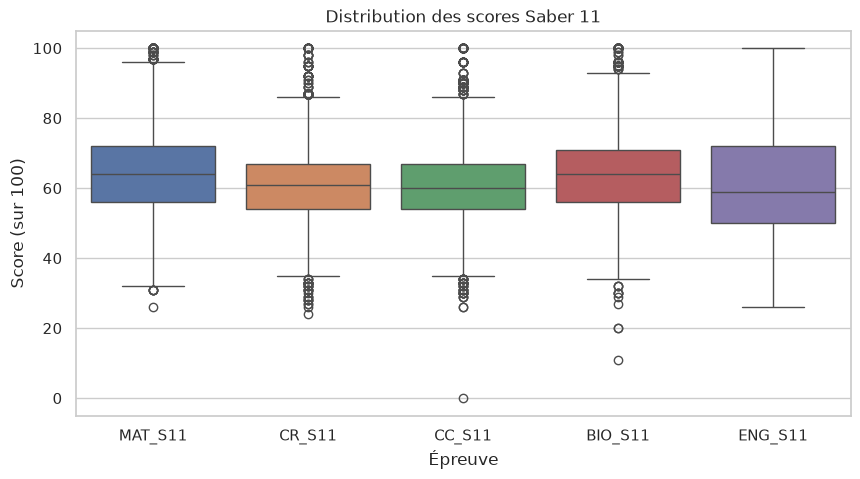

In [ ]:
# Distribution des scores du lycée
scores = ["MAT_S11", "CR_S11", "CC_S11", "BIO_S11", "ENG_S11"]

plt.figure(figsize=(10, 5))
sns.boxplot(data=df[scores])
plt.title("Distribution des scores Saber 11")
plt.xlabel("Épreuve")
plt.ylabel("Score (sur 100)")
plt.show()

Les cinq épreuves présentent des niveaux comparables. L'anglais est l'épreuve la plus dispersée et ne
présente aucune valeur isolée. Les points au-dessus des moustaches
correspondent à d'excellents élèves ; le score de 0 en compétences
citoyennes se détache nettement de toutes les autres valeurs.

In [ ]:
# Bornes IQR et nombre de valeurs hors bornes par épreuve
Q1 = df[scores].quantile(0.25)
Q3 = df[scores].quantile(0.75)
IQR = Q3 - Q1
borne_basse = Q1 - 1.5 * IQR
borne_haute = Q3 + 1.5 * IQR

hors_bornes = (df[scores] < borne_basse) | (df[scores] > borne_haute)
print(pd.DataFrame({"Borne basse": borne_basse,
                    "Borne haute": borne_haute,
                    "Sous la borne": (df[scores] < borne_basse).sum(),
                    "Au-dessus": (df[scores] > borne_haute).sum(),
                    "Minimum": df[scores].min(),
                    "Maximum": df[scores].max()}))
print("\nÉtudiants concernés :", hors_bornes.any(axis=1).sum())

# Élèves ayant au moins un score sous la borne basse, du plus bas au plus haut
sous_borne = (df[scores] < borne_basse).any(axis=1)
suspects = df[sous_borne][scores + ["G_SC"]]

print("Élèves concernés :", len(suspects))
suspects.assign(score_min=suspects[scores].min(axis=1)).sort_values("score_min").head(15)

         Borne basse  Borne haute  Sous la borne  Au-dessus  Minimum  Maximum
MAT_S11         32.0         96.0              6        131       26      100
CR_S11          34.5         86.5             34        162       24      100
CC_S11          34.5         86.5             40        167        0      100
BIO_S11         33.5         93.5             12        154       11      100
ENG_S11         17.0        105.0              0          0       26      100

Étudiants concernés : 588
Élèves concernés : 82


,MAT_S11,CR_S11,CC_S11,BIO_S11,ENG_S11,G_SC,score_min
2012,47,29,0,56,49,127,0
2329,51,36,47,11,54,173,11
1158,52,33,32,20,49,163,20
5449,40,47,44,20,42,126,20
3588,53,24,35,45,42,116,24
1237,58,26,35,48,71,167,26
1157,50,34,26,45,36,130,26
3015,53,35,26,45,30,127,26
9941,26,46,45,49,43,130,26
8091,32,27,40,40,44,118,27


D'autres scores très bas (par exemple 11 en biologie) sont conservés :
l'élève concerné présente des scores cohérents dans les autres épreuves et
un score global au-dessus de la médiane. Seul le 0, unique score nul du
dataset, s'apparente à une épreuve non passée.

In [ ]:
# Lignes supprimées : score nul en compétences citoyennes
a_supprimer = df[df["CC_S11"] == 0]

print("Lignes supprimées :", len(a_supprimer))
display(a_supprimer[scores + ["G_SC"]])

df = df.drop(a_supprimer.index)
print("Dimensions après traitement des valeurs aberrantes :", df.shape)

Lignes supprimées : 1


,MAT_S11,CR_S11,CC_S11,BIO_S11,ENG_S11,G_SC
2012,47,29,0,56,49,127


Dimensions après traitement des valeurs aberrantes : (12394, 31)


### 3.6 Normalisation et standardisation
La normalisation ramène chaque variable entre 0 et 1 ; la standardisation la
centre sur une moyenne de 0 avec un écart-type de 1. Ces transformations
servent aux algorithmes fondés sur des distances, pour qu'une variable aux
grandes valeurs n'écrase pas les autres.

L'arbre de décision compare une variable à un seuil, une variable à la fois :
il n'est pas sensible à l'échelle des données. Nous n'appliquons donc ni
normalisation ni standardisation. On aurait du l'appliquer si KNN par exemple ou régression linéaire.

### 3.7 Création de nouvelles colonnes
- `S11_moy` : moyenne des cinq scores Saber 11, qui résume le niveau général
  de l'étudiant au lycée.
- `faible` (**variable cible**) : vaut 1 si le score global Saber Pro est
  inférieur à **150**, 0 sinon.

Le Saber Pro n'a pas de seuil d'échec national : chaque université fixe le
score minimum exigé pour délivrer le diplôme, souvent au niveau de la
moyenne nationale. Nous retenons donc 150, moyenne de référence de l'échelle
(0 à 300). Un étudiant de classe 1 est **à risque de ne pas atteindre le
niveau exigé**, et de devoir repasser l'examen avant d'être diplômé.

In [ ]:
# Niveau général au lycée : moyenne des cinq scores de chaque étudiant
df["S11_moy"] = df[scores].mean(axis=1)

# Cible : 1 = score global sous la moyenne de référence nationale
SEUIL_FAIBLE = 150
df["faible"] = (df["G_SC"] < SEUIL_FAIBLE).astype(int)

print(df["faible"].value_counts())
print("Part de scores faibles :", round(df["faible"].mean() * 100, 1), "%")
print("Dimensions :", df.shape)

faible
0    8798
1    3596
Name: count, dtype: int64
Part de scores faibles : 29.0 %
Dimensions : (12394, 33)


29 % des étudiants obtiennent un score inférieur à la moyenne nationale de
référence. La cible est déséquilibrée (71 % / 29 %)

## Étape 4 : Data analysis
Nous étudions cinq questions, chacune liée au besoin métier : comprendre
quels étudiants sont à risque d'obtenir un score inférieur à 150.
La variable `faible` valant 0 ou 1, sa moyenne au sein d'un groupe donne
directement la **part d'étudiants à risque** dans ce groupe.

### Question 1 : Le niveau au lycée annonce-t-il le risque ?

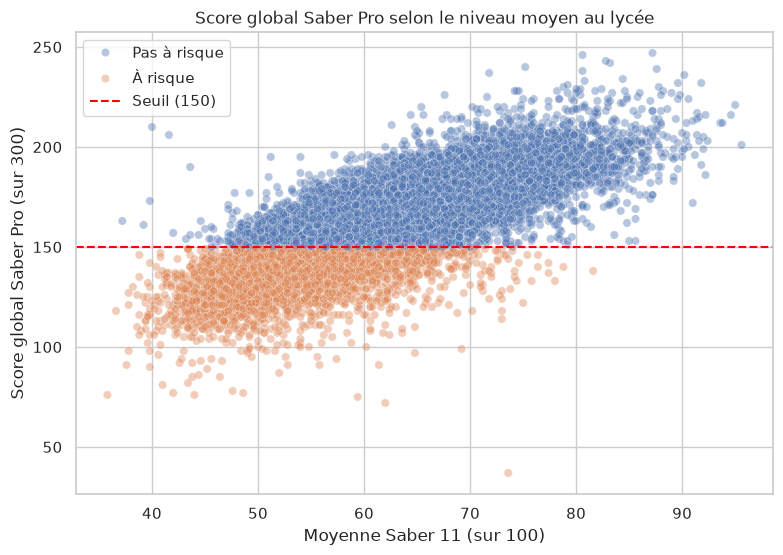

In [ ]:
# Score global en fonction du niveau moyen au lycée
plt.figure(figsize=(9, 6))
statut = df["faible"].map({0: "Pas à risque", 1: "À risque"})
sns.scatterplot(x=df["S11_moy"], y=df["G_SC"], hue=statut, alpha=0.4)
plt.axhline(SEUIL_FAIBLE, color="red", linestyle="--", label="Seuil (150)")
plt.title("Score global Saber Pro selon le niveau moyen au lycée")
plt.xlabel("Moyenne Saber 11 (sur 100)")
plt.ylabel("Score global Saber Pro (sur 300)")
plt.legend()
plt.show()

Le graphique distingue trois zones : sous 50 de moyenne au lycée, les
étudiants sont presque tous à risque ; au-dessus de 75, presque aucun ne
l'est. Entre 50 et 70, les deux groupes se chevauchent : à niveau égal,
d'autres facteurs interviennent. Les questions suivantes cherchent à les
identifier.

### Question 2 : Quelle matière du lycée distingue le mieux les étudiants à risque ?

In [ ]:
# Score moyen par matière selon le statut de l'étudiant
moyennes = df.groupby("faible")[scores].mean().round(1)
moyennes.index = ["Pas à risque", "À risque"]
moyennes.loc["Écart"] = moyennes.loc["À risque"] - moyennes.loc["Pas à risque"]
moyennes

,MAT_S11,CR_S11,CC_S11,BIO_S11,ENG_S11
Pas à risque,68.0,64.1,63.9,67.6,66.1
À risque,55.4,52.8,53.0,55.0,51.4
Écart,-12.6,-11.3,-10.9,-12.6,-14.7


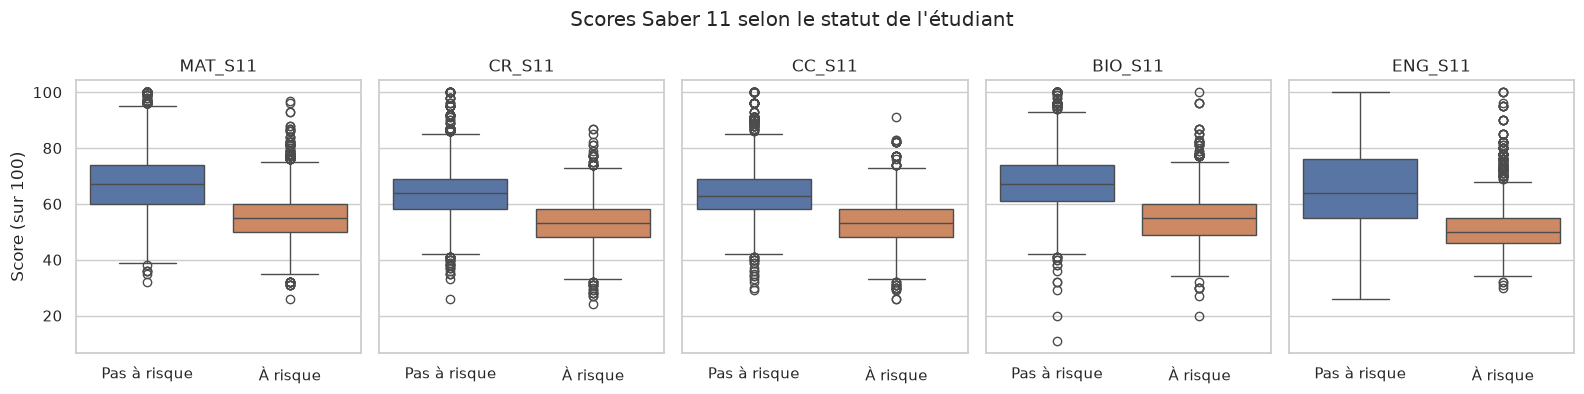

In [ ]:
# Distribution de chaque matière selon le statut
statut = df["faible"].map({0: "Pas à risque", 1: "À risque"})

fig, axes = plt.subplots(1, 5, figsize=(16, 4), sharey=True)
for ax, matiere in zip(axes, scores):
    sns.boxplot(x=statut, y=df[matiere], hue=statut, legend=False, ax=ax)
    ax.set_title(matiere)
    ax.set_xlabel("")
axes[0].set_ylabel("Score (sur 100)")
plt.suptitle("Scores Saber 11 selon le statut de l'étudiant")
plt.tight_layout()
plt.show()

En anglais, les étudiants à risque se concentrent dans une plage étroite, alors que les autres sont très
dispersés.

### Question 3 : Le milieu social influence-t-il le risque ?
Nous comparons, pour chaque strate du logement (de 1, la plus modeste, à 6,
la plus aisée), la part d'étudiants à risque à l'université et leur niveau
moyen au lycée. Si les deux évoluent ensemble, l'inégalité sociale est déjà
présente avant l'entrée à l'université.

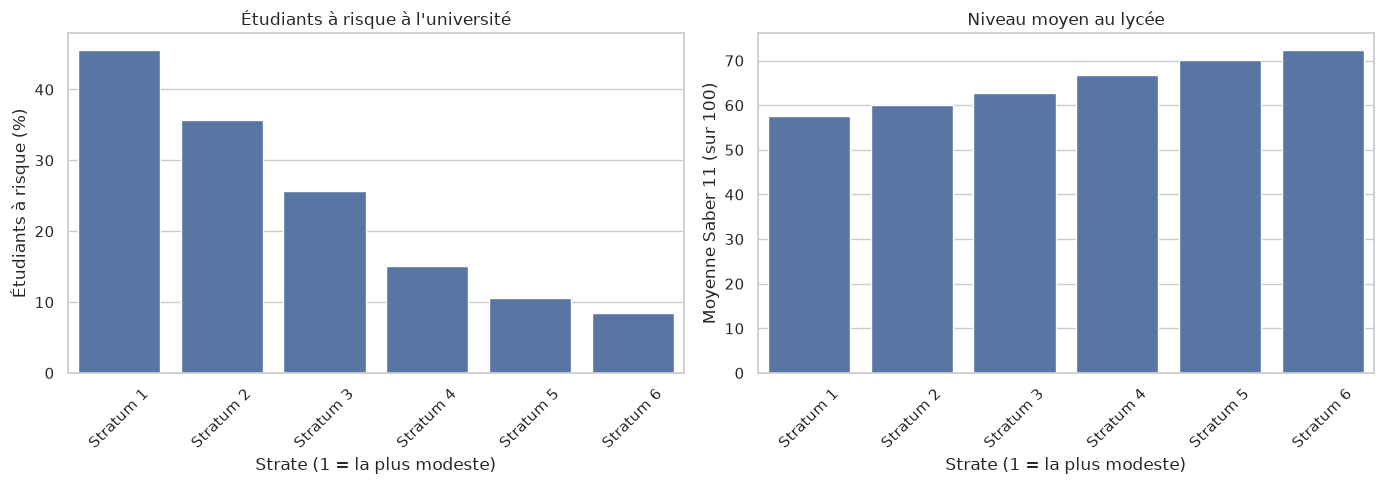

,etudiants,risque_pct,niveau_lycee
STRATUM,,,
Stratum 1,1707,45.6,57.6
Stratum 2,4025,35.7,60.0
Stratum 3,4052,25.7,62.7
Stratum 4,1575,15.1,66.9
Stratum 5,632,10.6,70.1
Stratum 6,403,8.4,72.5


In [ ]:
# Par strate : part d'étudiants à risque et niveau moyen au lycée
ordre_strates = ["Stratum 1", "Stratum 2", "Stratum 3", "Stratum 4", "Stratum 5", "Stratum 6"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=df["STRATUM"], y=df["faible"] * 100, order=ordre_strates, errorbar=None, ax=axes[0])
axes[0].set_title("Étudiants à risque à l'université")
axes[0].set_ylabel("Étudiants à risque (%)")

sns.barplot(x=df["STRATUM"], y=df["S11_moy"], order=ordre_strates, errorbar=None, ax=axes[1])
axes[1].set_title("Niveau moyen au lycée")
axes[1].set_ylabel("Moyenne Saber 11 (sur 100)")

for ax in axes:
    ax.set_xlabel("Strate (1 = la plus modeste)")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


# Valeurs exactes par strate
df.groupby("STRATUM").agg(
    etudiants=("faible", "size"),
    risque_pct=("faible", "mean"),
    niveau_lycee=("S11_moy", "mean"),
).assign(risque_pct=lambda t: t["risque_pct"] * 100).round(1)

**Réponse :** la part d'étudiants à risque diminue avec la strate
sociale qui augmente : de **45,6 %** dans la strate 1 à **8,4 %** dans la strate 6, soit un
risque plus de cinq fois plus élevé pour les étudiants les plus modestes. Dans
le même temps, le niveau moyen au lycée progresse de **57,6** à **72,5**.

L'inégalité sociale est donc déjà visible en sortie de lycée : les étudiants
des strates modestes arrivent à l'université avec un niveau plus faible, ce
qui explique en grande partie leur risque plus élevé. Le niveau au lycée et
la strate étant liés, le modèle utilisera les deux variables.

Les strates 5 et 6 regroupent moins de 1 100 étudiants (8 % du dataset) :
leurs pourcentages restent fiables, mais reposent sur des effectifs plus
réduits.

### Question 4 : Le type de lycée influence-t-il le risque ?
Même démarche que pour la question 3 : nous comparons, pour les lycées publics
et privés, la part d'étudiants à risque à l'université et le niveau moyen au
lycée.

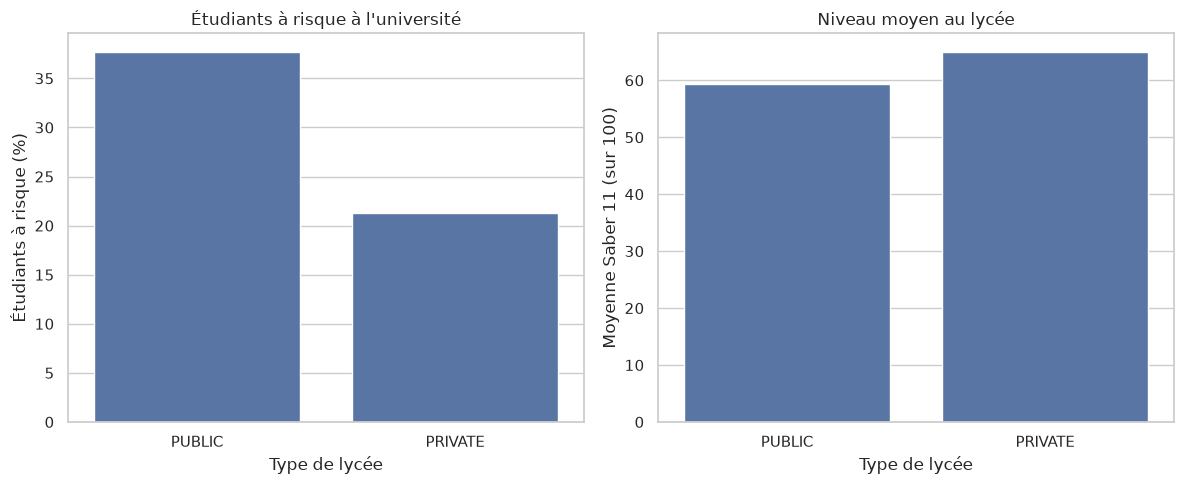

In [ ]:
# Par type de lycée : part d'étudiants à risque et niveau moyen au lycée
ordre_lycees = ["PUBLIC", "PRIVATE"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(x=df["SCHOOL_NAT"], y=df["faible"] * 100, order=ordre_lycees, errorbar=None, ax=axes[0])
axes[0].set_title("Étudiants à risque à l'université")
axes[0].set_ylabel("Étudiants à risque (%)")

sns.barplot(x=df["SCHOOL_NAT"], y=df["S11_moy"], order=ordre_lycees, errorbar=None, ax=axes[1])
axes[1].set_title("Niveau moyen au lycée")
axes[1].set_ylabel("Moyenne Saber 11 (sur 100)")

for ax in axes:
    ax.set_xlabel("Type de lycée")
plt.tight_layout()
plt.show()




In [ ]:
# Valeurs exactes par type de lycée
df.groupby("SCHOOL_NAT").agg(
    etudiants=("faible", "size"),
    risque_pct=("faible", "mean"),
    niveau_lycee=("S11_moy", "mean"),
).assign(risque_pct=lambda t: t["risque_pct"] * 100).round(1)

,etudiants,risque_pct,niveau_lycee
SCHOOL_NAT,,,
PRIVATE,6556,21.3,65.0
PUBLIC,5838,37.7,59.3


**Réponse :** les étudiants issus d'un lycée public sont nettement plus souvent
à risque (**37,7 %**) que ceux issus du privé (**21,3 %**), soit près de deux
fois plus. Leur niveau moyen au lycée est également plus faible (**59,3**
contre **65,0**).

Comme pour la strate sociale, l'écart de risque à l'université reflète en
grande partie un écart de niveau déjà présent en sortie de lycée.

### Question 5 : Toutes les spécialités d'ingénierie sont-elles égales face au risque ?
Le dataset compte 21 spécialités, dont la plupart regroupent moins de 100
étudiants : leurs pourcentages ne seraient pas fiables. Nous retenons les
spécialités d'au moins 200 étudiants, puis comparons, comme aux questions
précédentes, la part d'étudiants à risque et le niveau moyen au lycée.

In [ ]:
# Spécialités d'au moins 200 étudiants
effectifs = df["ACADEMIC_PROGRAM"].value_counts()
specialites = effectifs[effectifs >= 200].index
df_spec = df[df["ACADEMIC_PROGRAM"].isin(specialites)]

print("Spécialités retenues :", len(specialites))
print("Part du dataset couverte :", round(len(df_spec) / len(df) * 100, 1), "%")

Spécialités retenues : 6
Part du dataset couverte : 95.9 %


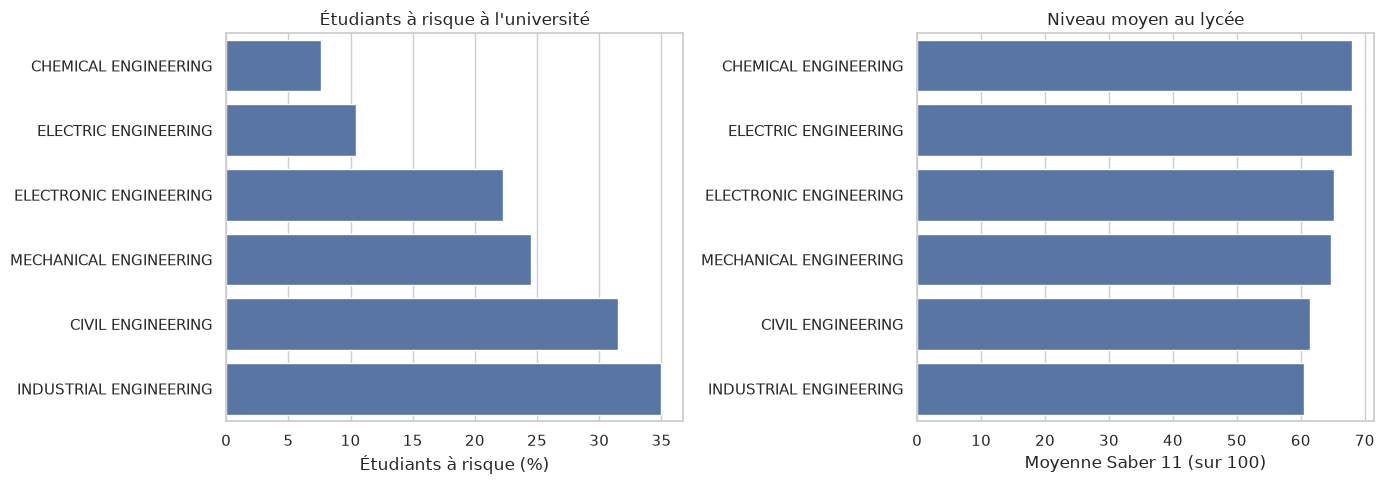

In [ ]:
# Par spécialité : part d'étudiants à risque et niveau moyen au lycée
ordre_spec = df_spec.groupby("ACADEMIC_PROGRAM")["faible"].mean().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(y=df_spec["ACADEMIC_PROGRAM"], x=df_spec["faible"] * 100, order=ordre_spec, errorbar=None, ax=axes[0])
axes[0].set_title("Étudiants à risque à l'université")
axes[0].set_xlabel("Étudiants à risque (%)")

sns.barplot(y=df_spec["ACADEMIC_PROGRAM"], x=df_spec["S11_moy"], order=ordre_spec, errorbar=None, ax=axes[1])
axes[1].set_title("Niveau moyen au lycée")
axes[1].set_xlabel("Moyenne Saber 11 (sur 100)")

for ax in axes:
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [ ]:
# Valeurs exactes par spécialité, triées par risque croissant
df_spec.groupby("ACADEMIC_PROGRAM").agg(
    etudiants=("faible", "size"),
    risque_pct=("faible", "mean"),
    niveau_lycee=("S11_moy", "mean"),
).assign(risque_pct=lambda t: t["risque_pct"] * 100).round(1).sort_values("risque_pct")

,etudiants,risque_pct,niveau_lycee
ACADEMIC_PROGRAM,,,
CHEMICAL ENGINEERING,1000,7.6,68.0
ELECTRIC ENGINEERING,278,10.4,68.0
ELECTRONIC ENGINEERING,848,22.3,65.1
MECHANICAL ENGINEERING,1133,24.5,64.8
CIVIL ENGINEERING,3310,31.5,61.4
INDUSTRIAL ENGINEERING,5314,35.0,60.5


**Réponse :** non. La part d'étudiants à risque varie fortement d'une spécialité
à l'autre : de **7,6 %** en génie chimique à **35,0 %** en génie industriel,
soit un risque plus de quatre fois plus élevé. Les spécialités les plus à
risque sont aussi celles dont les étudiants présentent le niveau au lycée le
plus faible (**60,5** en génie industriel contre **68,0** en génie chimique).

Le génie industriel et le génie civil regroupent **70 %** des étudiants
(8 624 sur 12 394) et présentent le risque le plus élevé : ce sont les
spécialités où un accompagnement aurait le plus d'impact.

### Synthèse de l'analyse
| Question | Constat |
|---|---|
| 1. Niveau au lycée | 74 % de risque pour le quart le plus faible au lycée, 2 % pour le quart le plus fort |
| 2. Matière la plus discriminante | L'anglais (écart de 14,7 points), mais toutes les matières comptent |
| 3. Milieu social | Risque de 45,6 % (strate 1) à 8,4 % (strate 6), lié à un niveau au lycée plus faible |
| 4. Type de lycée | 37,7 % de risque (public) contre 21,3 % (privé), lié au niveau au lycée |
| 5. Spécialité | De 7,6 % (chimie) à 35,0 % (industriel) ; génie industriel et civil = 70 % des étudiants |

**Fil conducteur :** le niveau atteint au lycée est le premier indicateur du
risque. Le milieu social et le type de lycée influencent ce niveau, et donc
indirectement le risque.

### Variables retenues pour le modèle
| Variable | Justification |
|---|---|
| `MAT_S11`, `CR_S11`, `CC_S11`, `BIO_S11`, `ENG_S11` | Indicateurs principaux du risque (questions 1 et 2) |
| `STRATUM` | Liée au risque et au niveau au lycée (question 3) |
| `SCHOOL_NAT` | Liée au risque et au niveau au lycée (question 4) |

`ACADEMIC_PROGRAM` n'est pas retenue : ses 21 modalités n'ont pas d'ordre, et
l'écart entre spécialités s'explique en grande partie par le niveau au lycée.
Elle reste utile pour **cibler** l'accompagnement, mais pas pour prédire.
`S11_moy` n'est pas retenue non plus : elle résume les cinq scores, déjà
présents dans le modèle.

# Partie 2
## Étape 5 : Application d'un algorithme de Machine Learning
Nous construisons d'abord un arbre de décision avec les paramètres par défaut,
puis nous l'optimisons. Les deux versions sont évaluées sur le même jeu de
test, ce qui permet de mesurer l'apport de l'optimisation.

### 5.1 Choix de l'algorithme
Le problème est une classification : à partir de données
étiquetées, prédire si un étudiant appartient à la classe « à risque »
(score Saber Pro inférieur à 150) ou non.

Nous retenons l'**arbre de décision**, pour sa lisibilité : le modèle prend la forme de règles explicites, directement
  exploitables par l'université pour cibler l'accompagnement.

In [ ]:
#Import des librairies nécessaires
# Modél et évaluation
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn import metrics


### 5.2 Sélection des variables
Les variables explicatives retenues sont les cinq
scores Saber 11, la strate sociale et le type de lycée. La variable cible est
`faible`.

Le modèle n'accepte que des valeurs numériques donc `STRATUM` (« Stratum 1 » à
« Stratum 6 ») est converti en 1 à 6, ce qui conserve l'ordre des strates, et
`SCHOOL_NAT` en 0 (école publique) / 1 (école privée).

In [ ]:
# Correspondances texte → nombre
strate_map = {"Stratum 1": 1, "Stratum 2": 2, "Stratum 3": 3,
              "Stratum 4": 4, "Stratum 5": 5, "Stratum 6": 6}
lycee_map = {"PUBLIC": 0, "PRIVATE": 1}

df["STRATUM"] = df["STRATUM"].map(strate_map)
df["SCHOOL_NAT"] = df["SCHOOL_NAT"].map(lycee_map)

# Si NaN alors valeur manquante
print("Valeurs non converties :", df[["STRATUM", "SCHOOL_NAT"]].isnull().sum().sum())

Valeurs non converties : 0


In [ ]:
# Variables explicatives (X) et variable cible (y)
features = ["MAT_S11", "CR_S11", "CC_S11", "BIO_S11", "ENG_S11", "STRATUM", "SCHOOL_NAT"]

X = df[features]
# 1 === élève à risque d'echouer
y = df["faible"]

print("Dimensions de X :", X.shape)
print(y.value_counts())

Dimensions de X : (12394, 7)
faible
0    8798
1    3596
Name: count, dtype: int64


### 5.3 Séparation des données
Les données sont divisées en un jeu d'**entraînement** (70 %) et un jeu de
**test** (30 %), réservé à l'évaluation sur des étudiants que le modèle n'a
jamais vus. La cible étant déséquilibrée (71 % / 29 %), la séparation est
**stratifiée** : les deux jeux conservent la proportion réelle d'étudiants
à risque.

In [ ]:
# Graine aléatoire commune, pour des résultats reproductibles
RANDOM_STATE = 42

In [ ]:
# Séparation 70 / 30, stratifiée sur la cible
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

#On cherche à garder le vrai équilibre entre les valeurs
print("Entraînement :", X_train.shape, "| Test :", X_test.shape)
print("Part d'étudiants à risque - entraînement :", round(y_train.mean() * 100, 1), "%")
print("Part d'étudiants à risque - test :", round(y_test.mean() * 100, 1), "%")

Entraînement : (8675, 7) | Test : (3719, 7)
Part d'étudiants à risque - entraînement : 29.0 %
Part d'étudiants à risque - test : 29.0 %


### 5.4 Construction du modèle
Un premier arbre est entraîné avec les **paramètres par défaut** : critère de
Gini, aucune limite de profondeur.

In [ ]:
# Création de l'arbre de décision
arbre_base = DecisionTreeClassifier(random_state=RANDOM_STATE)

# Entraînement
arbre_base = arbre_base.fit(X_train, y_train)

# Prédiction sur le jeu de test
y_pred_base = arbre_base.predict(X_test)

### 5.5 Évaluation du modèle


In [ ]:
print("Profondeur :", arbre_base.get_depth(), "| Nombre de feuilles :", arbre_base.get_n_leaves())
# Évaluation sur le jeu de test
print("Accuracy :", round(metrics.accuracy_score(y_test, y_pred_base), 3))

Profondeur : 23 | Nombre de feuilles : 1653
Accuracy : 0.75


L'arbre a une profondeur de 23 et classe correctement **75,0 %** des étudiants du jeu de test. C'est beaucoup pour la profondeur on peut optimiser le modèle mais décent pour l'accuracy

Profondeur : 23 | Nombre de feuilles : 1653


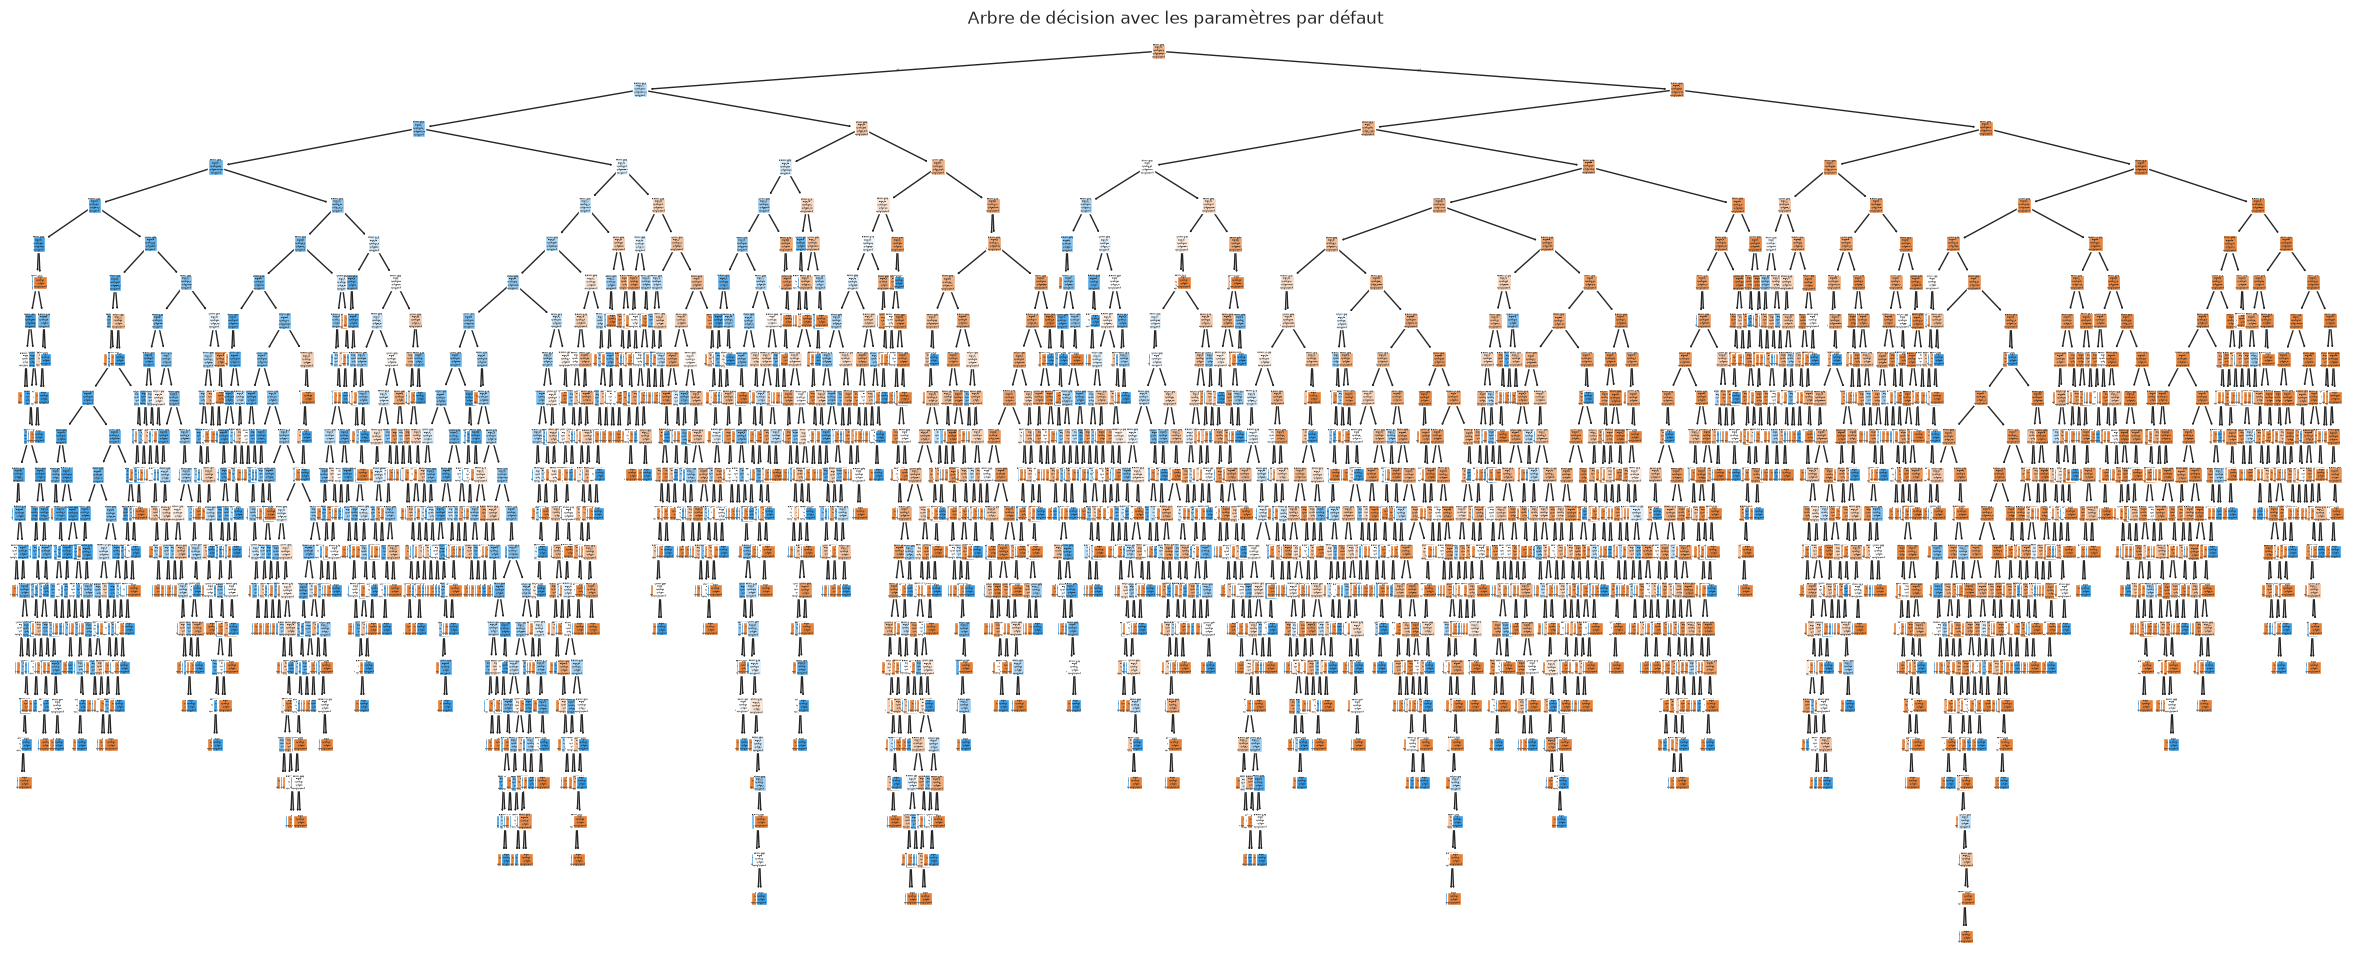

In [ ]:
# Arbre de décision complet
print("Profondeur :", arbre_base.get_depth(), "| Nombre de feuilles :", arbre_base.get_n_leaves())

plt.figure(figsize=(30, 12))
plot_tree(arbre_base, feature_names=features,
          class_names=["Pas à risque", "À risque"], filled=True)
plt.title("Arbre de décision avec les paramètres par défaut")
plt.show()

### 5.6 Visualisation de l'arbre
L'arbre compte **23 niveaux et 1 653 feuilles** : il est illisible. Sans limite
de profondeur, il multiplie les règles très précises, qui décrivent des cas
particuliers des données d'entraînement.
Un tel modèle ne permet pas à l'université d'en tirer des consignes
d'accompagnement. Il faut l'optimiser.

### 5.7 Optimisation du modèle
Deux paramètres sont ajustés :
- `criterion="entropy"` : les séparations sont choisies selon le **gain
  d'information**, c'est-à-dire la baisse d'entropie obtenue ;
- `max_depth` : la profondeur maximale de l'arbre, pour qu'il retienne des
  règles générales et reste lisible.

#### Choix de la profondeur
Il n'existe pas de valeur idéale a priori : nous testons des profondeurs de 1
à 10. Pour chacune, l'accuracy est estimée par **validation croisée** sur le
jeu d'entraînement : celui-ci est découpé en 5 parties ; le modèle est entraîné
sur 4 et évalué sur la 5e, cinq fois de suite, et les 5 scores sont moyennés.
Le jeu de test reste ainsi intact pour l'évaluation finale. Nous relevons
également le nombre de feuilles, c'est-à-dire de règles, de chaque arbre.

In [ ]:
# Pour chaque profondeur : accuracy en validation croisée, nombre de règles
# et nombre d'étudiants par feuille
profondeurs = range(1, 10)
scores_cv = []
nb_feuilles = []
etudiants_moyen = []
etudiants_min = []

for p in profondeurs:
    arbre = DecisionTreeClassifier(criterion="entropy", max_depth=p, random_state=RANDOM_STATE)
    scores_cv.append(cross_val_score(arbre, X_train, y_train, cv=5).mean())

    arbre.fit(X_train, y_train)
    noeuds = arbre.tree_
    effectifs_feuilles = noeuds.n_node_samples[noeuds.children_left == -1]

    nb_feuilles.append(arbre.get_n_leaves())
    etudiants_moyen.append(effectifs_feuilles.mean())
    etudiants_min.append(effectifs_feuilles.min())

resultats_profondeur = pd.DataFrame({"Profondeur": list(profondeurs),
                                     "Accuracy (validation croisée)": scores_cv,
                                     "Nombre de feuilles": nb_feuilles,
                                     "Étudiants par feuille (moyenne)": etudiants_moyen,
                                     "Étudiants par feuille (minimum)": etudiants_min})

resultats_profondeur = resultats_profondeur.round({"Accuracy (validation croisée)": 3,
                                                   "Étudiants par feuille (moyenne)": 0})
resultats_profondeur["Étudiants par feuille (moyenne)"] = resultats_profondeur["Étudiants par feuille (moyenne)"].astype(int)
resultats_profondeur = resultats_profondeur.set_index("Profondeur")
resultats_profondeur

,Accuracy (validation croisée),Nombre de feuilles,Étudiants par feuille (moyenne),Étudiants par feuille (minimum)
Profondeur,,,,
1,0.784,2,4338,2807
2,0.800,4,2169,1309
3,0.810,8,1084,427
4,0.818,16,542,68
5,0.818,32,271,12
6,0.821,64,136,1
7,0.818,115,75,1
8,0.814,189,46,1
9,0.808,280,31,1


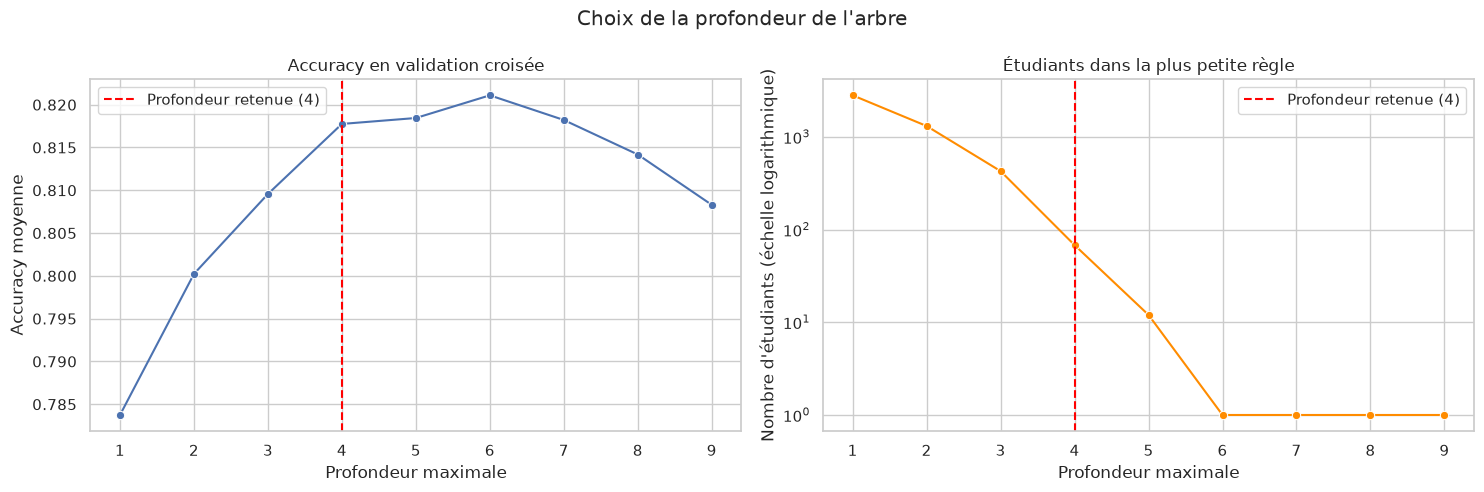

In [ ]:
# Accuracy et nombre minimum d'étudiants par règle selon la profondeur
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy en validation croisée
sns.lineplot(x=list(profondeurs), y=scores_cv, marker="o", ax=axes[0])
axes[0].set_title("Accuracy en validation croisée")
axes[0].set_ylabel("Accuracy moyenne")

# Nombre d'étudiants dans la plus petite règle (échelle logarithmique)
sns.lineplot(x=list(profondeurs), y=etudiants_min, marker="o", color="darkorange", ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Étudiants dans la plus petite règle")
axes[1].set_ylabel("Nombre d'étudiants (échelle logarithmique)")

for ax in axes:
    ax.axvline(4, color="red", linestyle="--", label="Profondeur retenue (4)")
    ax.set_xlabel("Profondeur maximale")
    ax.set_xticks(list(profondeurs))
    ax.legend()

plt.suptitle("Choix de la profondeur de l'arbre")
plt.tight_layout()
plt.show()

Jusqu'à 4 niveaux, l'accuracy progresse et la plus petite règle repose encore
sur 68 étudiants. Au-delà, l'accuracy plafonne, tandis que la plus petite règle
ne concerne plus que 12 étudiants (profondeur 5), puis **un seul** à partir de
la profondeur 6 : l'arbre crée alors des règles pour des cas isolés. La
profondeur 4 offre la meilleure performance pour des règles qui restent fiables.